# Importar pacotes de interesse

In [66]:
import pandas as pd
import numpy as np
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load

# Funções que integram a pipeline:
    - prepara_df
    - separa_train_test_val
    - preparar_e_escalar_dados
    - constroi_modelo_tunable

In [67]:
# files_treinamento = ['050', '300', '400']
# files_teste = ['150']
files_treinamento = ['050', '150', '400']
files_teste = ['300']

In [ ]:
def prepara_df(tipo):
    # local = 'C:\\Users\\ymarc\\OneDrive\\Desktop\\ITA - 2025\\Mestrado\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'
    local = 'C:\\Users\\ymarc\\OneDrive\\Desktop\\ITA_2025\\Mestrado\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'

    if tipo=='treinamento': files = files_treinamento
    else: files = files_teste
    colunas = [
        'TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K', 'T', 'No. OBS.'
    ]

    all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=colunas) for file in files]

    # all_dfs = [pd.read_excel(local + file + '.xls').iloc[1:] for file in files]
    for i, item in enumerate(all_dfs): item['H'] = float(files[i])
    df = pd.concat(all_dfs, ignore_index=True)

    # imputer.fit(df)
    # df = pd.DataFrame(imputer.transform(df), columns=df.columns)

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['Pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['Pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    Pa0 = 1013.25
    df['delta'] = df['Pa']/Pa0
    df['T_over_delta'] = (df['T']*4.44822)/df['delta']

    S = 19.3
    df['D'] = df['Rho']*(df['Va']*0.5144)**2*S*df['CD']/2 # Arrasto em Newtons
    df['D_over_delta'] = df['D']/df['delta']

    return df

In [69]:
def separa_train_test_val():
    # Carrega os dados de treinamento ('050', '300', '400')
    dados_treinamento = prepara_df('treinamento')
    
    # Carrega os dados de teste ('150')
    Test_set = prepara_df('teste')

    # Separa o conjunto de treinamento em treino e validação
    Train_set, Val_set = train_test_split(dados_treinamento, test_size=0.2)
    
    return Train_set, Test_set, Val_set

Melhores Parâmetros determinados pelo grid_search:

{'batch_size': 32, 'epochs': 60, 'model__learning_rate': 0.0001, 'model__neurons': 60, 'model__optimizer': 'adam'}

Melhor Score (MAE Negativo): -0.0009

Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0009

# Pipeline Modular para Modelos Separados

Aqui implementamos uma pipeline modular que permite treinar modelos separados para CD e T de forma flexível e reutilizável.


In [70]:
def preparar_dados_parametro(train_set, test_set, val_set, features_entrada, parametro_alvo):
    """
    Prepara dados específicos para um parâmetro
    """
    # Features de entrada
    X_train = train_set[features_entrada].copy()
    X_test = test_set[features_entrada].copy()
    X_val = val_set[features_entrada].copy()
    
    # Parâmetro alvo
    Y_train = train_set[[parametro_alvo]].copy()
    Y_test = test_set[[parametro_alvo]].copy()
    Y_val = val_set[[parametro_alvo]].copy()
    
    # Criar scalers
    scaler_X = MinMaxScaler()
    scaler_Y = MinMaxScaler()
    
    # Escalar dados
    X_train_scaled = scaler_X.fit_transform(X_train)
    Y_train_scaled = scaler_Y.fit_transform(Y_train)
    
    X_test_scaled = scaler_X.transform(X_test)
    Y_test_scaled = scaler_Y.transform(Y_test)
    
    X_val_scaled = scaler_X.transform(X_val)
    Y_val_scaled = scaler_Y.transform(Y_val)
    
    dados_escalados = (X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled, X_val_scaled, Y_val_scaled)
    scalers = (scaler_X, scaler_Y)
    
    return dados_escalados, scalers


In [71]:
def constroi_modelo_parametro(parametro_alvo, features_entrada, arquitetura, hiperparametros):
    """
    Constrói modelo específico para um parâmetro
    """
    input_shape = (len(features_entrada),)
    
    model = keras.Sequential()
    
    # Camadas ocultas
    for i in range(arquitetura['camadas_ocultas']):
        model.add(layers.Dense(
            arquitetura['neurons'], 
            input_shape=input_shape if i == 0 else None,
            activation=arquitetura['activation'],
            name=f'oculta_{i+1}_{parametro_alvo}'
        ))
        
        if arquitetura['dropout'] > 0:
            model.add(layers.Dropout(arquitetura['dropout']))
    
    # Camada de saída
    model.add(layers.Dense(1, name=f'saida_{parametro_alvo}'))
    
    # Compilar modelo
    if hiperparametros['optimizer'] == 'adam':
        opt = Adam(learning_rate=hiperparametros['learning_rate'])
    else:
        opt = RMSprop(learning_rate=hiperparametros['learning_rate'])
    
    model.compile(loss="mae", optimizer=opt, metrics=["mae"])
    
    return model


In [72]:
def treinar_modelo_parametro(modelo, dados_escalados, hiperparametros):
    """
    Treina o modelo com os dados fornecidos
    """
    X_train, Y_train, _, _, X_val, Y_val = dados_escalados
    
    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss', 
        patience=hiperparametros['patience']
    )
    
    historico = modelo.fit(
        X_train, Y_train,
        epochs=hiperparametros['epochs'],
        batch_size=hiperparametros['batch_size'],
        callbacks=[callback],
        validation_data=(X_val, Y_val),
        verbose=0
    )
    
    return historico


In [74]:
def avaliar_modelo(modelo, dados, scalers):
    """
    Avalia o desempenho do modelo
    """
    # Desempacotar dados de teste
    _, _, X_test, Y_test, _, _ = dados
    
    # Fazer predições
    pred_scaled = modelo.predict(X_test)
    
    # Desnormalizar
    pred = scalers[1].inverse_transform(pred_scaled).flatten()
    
    real = scalers[1].inverse_transform(Y_test).flatten()
    
    # Calcular métricas
    erro = (pred - real) * 100 / real
    
    resultados = {
        'predito': pred,
        'real': real,
        'erro_percentual': erro,
        'erro_medio': np.mean(erro)
    }
    
    return resultados


In [75]:
def pipeline_modular(parametro_alvo, features_entrada, arquitetura_modelo=None, 
                    hiperparametros=None, dados_treinamento=None):
    """
    Pipeline modular para treinar modelos de rede neural para diferentes parâmetros
    
    Args:
        parametro_alvo (str): 'CD' ou 'T' - parâmetro a ser predito
        features_entrada (list): Lista de features de entrada (opcional)
        arquitetura_modelo (dict): Configuração da arquitetura (opcional)
        hiperparametros (dict): Hiperparâmetros de treinamento (opcional)
        dados_treinamento (tuple): Dados já preparados (opcional)
    
    Returns:
        tuple: (modelo_treinado, dados_escalados, scalers, historico_treinamento)
    """
    
    # Configurações padrão
    # if features_entrada is None:
    #     features_entrada = ['NG', 'W', 'Zp', 'Mach', 'Va', 'Ta', 'CL']
    
    if arquitetura_modelo is None:
        print('arquitetura_modelo is None')
        arquitetura_modelo = {
            'neurons': 60,
            'camadas_ocultas': 2,
            'activation': 'relu',
            'dropout': 0.0
        }
    
    if hiperparametros is None:
        print('hiperparametros is None')
        hiperparametros = {
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 60,
            'batch_size': 32,
            'patience': 3
        }
    
    # Preparar dados se não fornecidos
    if dados_treinamento is None:
        Train_set, Test_set, Val_set = separa_train_test_val()
    else:
        Train_set, Test_set, Val_set = dados_treinamento
    
    # Preparar dados específicos para o parâmetro
    dados_escalados, scalers = preparar_dados_parametro(
        Train_set, Test_set, Val_set, 
        features_entrada, parametro_alvo
    )
    
    # Construir modelo específico
    modelo = constroi_modelo_parametro(
        parametro_alvo, features_entrada, arquitetura_modelo, hiperparametros
    )
    
    # Treinar modelo
    historico = treinar_modelo_parametro(
        modelo, dados_escalados, hiperparametros
    )
    
    return modelo, dados_escalados, scalers, historico


In [ ]:
# from tkinter import _EntryValidateCommand


def comparar_abordagens(abordagem):
    """
    Compara a abordagem unificada vs. separada
    """
    print("=== COMPARAÇÃO DE ABORDAGENS ===\n")
    
    # Preparar dados uma vez
    Train_set, Test_set, Val_set = separa_train_test_val()
    dados_compartilhados = (Train_set, Test_set, Val_set)

    entrada_drag = ['Mach', 'CL']
    if abordagem == 'CD_T':
        saida_drag = 'CD'
        entrada_T = ['NG', 'W', 'Zp', 'Mach', 'Ta_K']
        saida_T = 'T'
    elif abordagem == 'over_delta':
        saida_drag = 'D_over_delta'
        entrada_T = ['Mach', 'N1_over_sqrt_theta']
        saida_T = 'T_over_delta'
    
    # Configurações específicas para cada modelo
    config_drag = {
        # 'features_entrada': ['Mach', 'CL'],
        'features_entrada': entrada_drag,
        'arquitetura_modelo': {
            'neurons': 60,
            'camadas_ocultas': 2,
            'activation': 'relu',
            'dropout': 0.1
        },
        'hiperparametros': {
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 60,
            'batch_size': 32,
            'patience': 3
        }
    }
    
    config_tracao = {
        # 'features_entrada': ['NG', 'W', 'Zp', 'Mach', 'Ta_K'],
        # 'features_entrada': ['Mach', 'N1_over_sqrt_theta'],
        'features_entrada': entrada_T,
        'arquitetura_modelo': {
            'neurons': 60,
            'camadas_ocultas': 2,
            'activation': 'relu',
            'dropout': 0.1
        },
        'hiperparametros': {
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 60,
            'batch_size': 32,
            'patience': 3
        }
    }

    # print(type(config_drag['saida']))
    
    # Treinar modelo para drag
    print("Treinando modelo para drag...")
    modelo_drag, dados_drag, scalers_drag, historico_drag = pipeline_modular(
        parametro_alvo=saida_drag, 
        dados_treinamento=dados_compartilhados,
        **config_drag
    )
    
    # Treinar modelo para tracao
    print("Treinando modelo para tracao...")
    modelo_tracao, dados_tracao, scalers_tracao, historico_tracao = pipeline_modular(
        parametro_alvo=saida_T,
        dados_treinamento=dados_compartilhados,
        **config_tracao
    )
    
    # Avaliar desempenho
    resultados = {
        'drag': avaliar_modelo(modelo_drag, dados_drag, scalers_drag),
        'tracao': avaliar_modelo(modelo_tracao, dados_tracao, scalers_tracao)
    }
    
    # # Exibir resultados
    # print(f"\n=== RESULTADOS ===")
    # print(f"Erro médio drag: {resultados['drag']['erro_medio']:.2f}%")
    # print(f"Erro médio tracao: {resultados['tracao']['erro_medio']:.2f}%")
    # print(f"Erro médio soma drag+tracao: {resultados['soma_drag_tracao']['erro_medio']:.2f}%")

    return modelo_drag, modelo_tracao, resultados, dados_drag, dados_tracao, scalers_drag, scalers_tracao


## Exemplo de Uso da Pipeline Modular

Agora vamos testar a pipeline modular treinando modelos separados para CD e T:


In [77]:
# Executar comparação de abordagens
# modelo_D_over_delta, modelo_T_over_delta, resultados, dados_D_over_delta, dados_T_over_delta, scalers_D_over_delta, scalers_T_over_delta = comparar_abordagens()
_, _, resultados_CD_T, _, _, _, _ = comparar_abordagens('CD_T')
_, _, resultados_over_delta, _, _, _, _ = comparar_abordagens('over_delta')


=== COMPARAÇÃO DE ABORDAGENS ===

Treinando modelo para drag...


c:\Users\ymarc\OneDrive\Desktop\ITA_2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Treinando modelo para tracao...


c:\Users\ymarc\OneDrive\Desktop\ITA_2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 454us/step
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 458us/step
=== COMPARAÇÃO DE ABORDAGENS ===

Treinando modelo para drag...


c:\Users\ymarc\OneDrive\Desktop\ITA_2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Treinando modelo para tracao...


c:\Users\ymarc\OneDrive\Desktop\ITA_2025\Mestrado\meVenv3_11\Lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 457us/step
321/321 ━━━━━━━━━━━━━━━━━━━━ 0s 463us/step


In [78]:
# # Visualizar histórico de treinamento dos modelos separados
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# # Histórico do modelo CD
# pd.DataFrame(historico_CD.history).plot(ax=ax1, title='Histórico de Treinamento - Modelo CD')
# ax1.grid(True)

# # Histórico do modelo T
# pd.DataFrame(historico_T.history).plot(ax=ax2, title='Histórico de Treinamento - Modelo T')
# ax2.grid(True)

# plt.tight_layout()
# plt.show()


CD e T:


C:\Users\ymarc\AppData\Local\Temp\ipykernel_6368\3102813121.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_6368\3102813121.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[3].legend()


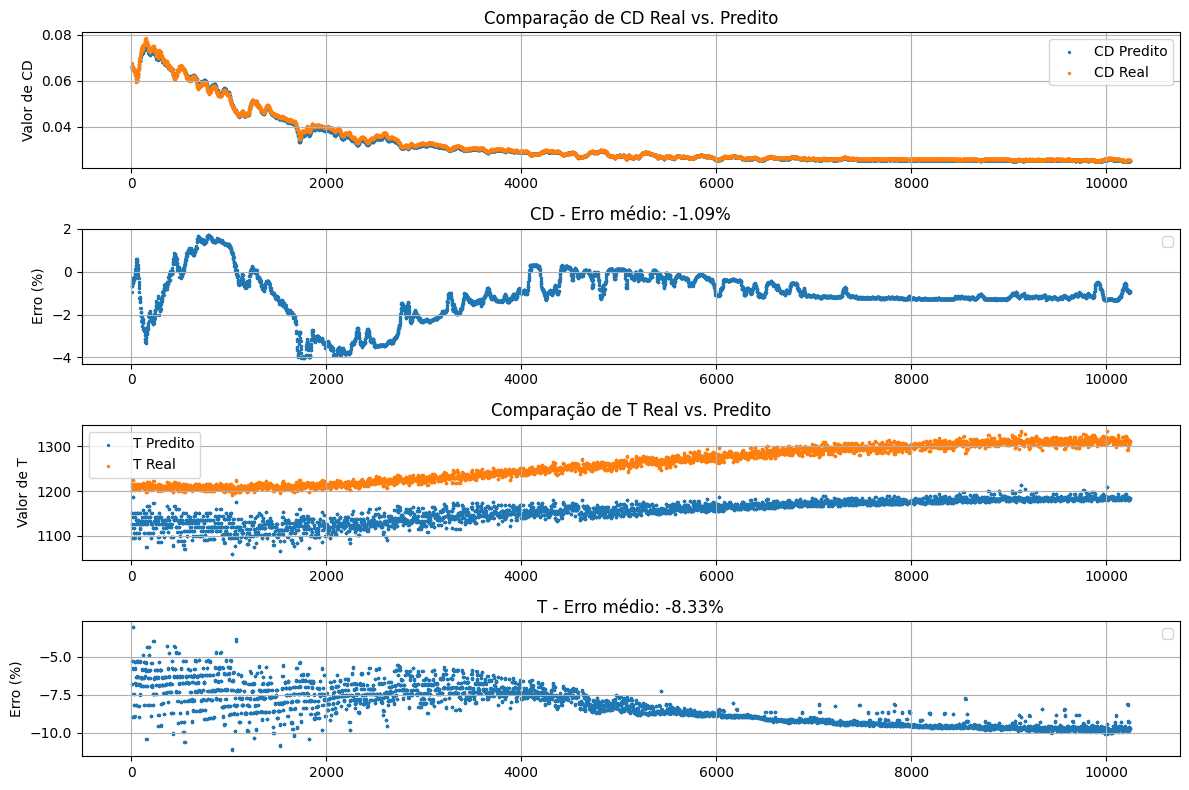

D/delta e T/delta:


C:\Users\ymarc\AppData\Local\Temp\ipykernel_6368\3102813121.py:43: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_6368\3102813121.py:68: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[3].legend()


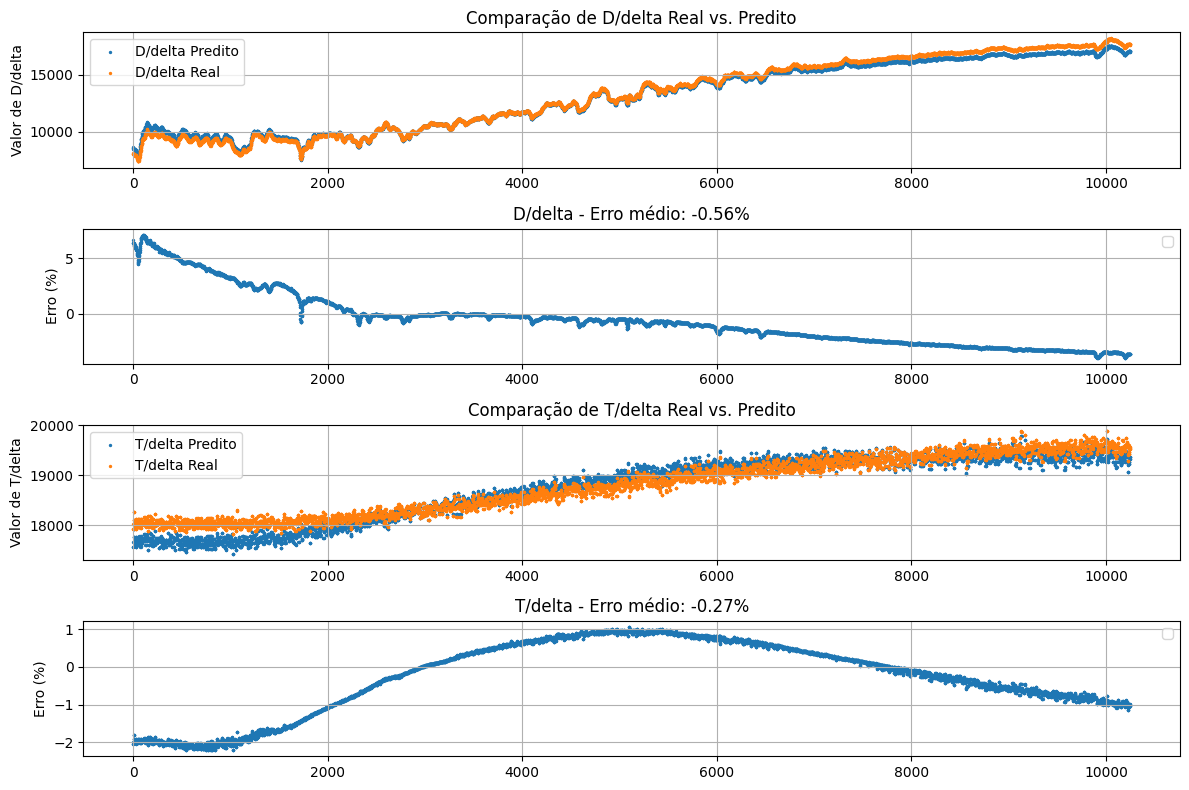

In [79]:
# Visualizar resultados dos modelos separados
import string


def exibir_resultados_separados(resultados, abordagem):
    """
    Exibe gráficos comparativos para os modelos separados
    """

    drag_pred=resultados['drag']['predito']
    drag_real=resultados['drag']['real']
    erro_drag=resultados['drag']['erro_percentual']
    tracao_pred=resultados['tracao']['predito']
    tracao_real=resultados['tracao']['real']
    erro_tracao=resultados['tracao']['erro_percentual']

    fig, axs = plt.subplots(4, 1, figsize=(12,8))

    index = prepara_df('test')['No. OBS.'].astype(int)
    sz=2
    
    if abordagem=='CD_T':
        axs[0].set_title('Comparação de CD Real vs. Predito')
        axs[0].scatter(index, drag_pred, sz, label='CD Predito')
        axs[0].scatter(index, drag_real, sz, label='CD Real')
        axs[0].set_ylabel('Valor de CD')
    else:
        axs[0].set_title('Comparação de D/delta Real vs. Predito')
        axs[0].scatter(index, drag_pred, sz, label='D/delta Predito')
        axs[0].scatter(index, drag_real, sz, label='D/delta Real')
        axs[0].set_ylabel('Valor de D/delta')
    axs[0].legend()
    axs[0].grid(True)
    
    
    axs[1].set_ylabel('Erro (%)')
    if abordagem=='CD_T':
        axs[1].set_title(f'CD - Erro médio: {resultados["drag"]["erro_medio"]:.2f}%')
        axs[1].scatter(index, erro_drag, sz)
    else:
        axs[1].set_title(f'D/delta - Erro médio: {resultados["drag"]["erro_medio"]:.2f}%')
        axs[1].scatter(index, erro_drag, sz)
    axs[1].legend()
    axs[1].grid(True)
    
    
    if abordagem=='CD_T':
        axs[2].set_title('Comparação de T Real vs. Predito')
        axs[2].scatter(index, tracao_pred, sz, label='T Predito')
        axs[2].scatter(index, tracao_real, sz, label='T Real')
        axs[2].set_ylabel('Valor de T')
    else:
        axs[2].set_title('Comparação de T/delta Real vs. Predito')
        axs[2].scatter(index, tracao_pred, sz, label='T/delta Predito')
        axs[2].scatter(index, tracao_real, sz, label='T/delta Real')
        axs[2].set_ylabel('Valor de T/delta')
    axs[2].legend()
    axs[2].grid(True)
    
    
    axs[3].set_ylabel('Erro (%)')
    if abordagem=='CD_T':
        axs[3].set_title(f'T - Erro médio: {resultados["tracao"]["erro_medio"]:.2f}%')
        axs[3].scatter(index, erro_tracao, sz)
    else:
        axs[3].set_title(f'T/delta - Erro médio: {resultados["tracao"]["erro_medio"]:.2f}%')
        axs[3].scatter(index, erro_tracao, sz)
    axs[3].legend()
    axs[3].grid(True)
    
    plt.tight_layout()
    plt.savefig(f'{abordagem}.png')
    plt.show()

# Exibir resultados
print('CD e T:')
exibir_resultados_separados(resultados_CD_T, "CD_T")
print('D/delta e T/delta:')
exibir_resultados_separados(resultados_over_delta, "over_delta")


## Função para Salvar Modelos Separados

Agora vamos criar uma função para salvar os modelos separados:


In [13]:
def salvar_modelos_separados(modelo_CD, modelo_T, scalers_CD, scalers_T, dados_CD, dados_T, prefixo=''):
    """
    Salva os modelos separados e seus componentes
    """
    # Salvar modelos
    modelo_CD.save(f'{prefixo}modelo_treinado_CD.keras')
    modelo_T.save(f'{prefixo}modelo_treinado_T.keras')
    
    # Salvar scalers
    dump(scalers_CD[0], f'{prefixo}scalerX_CD.joblib')
    dump(scalers_CD[1], f'{prefixo}scalerY_CD.joblib')
    dump(scalers_T[0], f'{prefixo}scalerX_T.joblib')
    dump(scalers_T[1], f'{prefixo}scalerY_T.joblib')
    
    # Salvar dados processados
    dump(dados_CD, f'{prefixo}Sets_std_CD.joblib')
    dump(dados_T, f'{prefixo}Sets_std_T.joblib')
    
    print(f"Modelos separados salvos com prefixo: {prefixo}")

# Exemplo de uso - salvar os modelos da primeira execução
# salvar_modelos_separados(modelo_CD, modelo_T, scalers_CD, scalers_T, dados_CD, dados_T)
